In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_csv(r"C:\Users\Dell\Downloads\retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 9


In [6]:
 df.head(10)

 

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


In [8]:
df.describe(include='all')

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,345,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,2023-05-16,CUST001,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,11,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
std,288.819436,NaN,NaN,NaN,13.68143,NaN,1.132734,189.681356,559.997632
min,1.000000,NaN,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,NaN,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,NaN,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,NaN,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000


In [9]:
original_rows = df.shape[0]
original_columns = df.shape[1]
original_missing = df.isnull().sum().sum()
original_duplicates = df.duplicated().sum()

print("Original rows:", original_rows)
print("Original columns:", original_columns)
print("Original missing values:", original_missing)
print("Original duplicate rows:", original_duplicates)


Original rows: 1000
Original columns: 9
Original missing values: 0
Original duplicate rows: 0


In [15]:
quality_report = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Missing Values': df.isnull().sum().values,
    'Missing %': ((df.isnull().sum() / len(df)) * 100).round(2).values,
    'Unique Values': df.nunique().values
})
quality_report

,Column,Data Type,Missing Values,Missing %,Unique Values
0,Transaction ID,int64,0,0.0,1000
1,Date,str,0,0.0,345
2,Customer ID,str,0,0.0,1000
3,Gender,str,0,0.0,2
4,Age,int64,0,0.0,47
5,Product Category,str,0,0.0,3
6,Quantity,int64,0,0.0,4
7,Price per Unit,int64,0,0.0,5
8,Total Amount,int64,0,0.0,18


In [17]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [19]:
missing = df.isnull().sum()
missing[missing > 0]


Series([], dtype: int64)

In [20]:
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include='object').columns

print("Numerical columns:")
print(list(numeric_columns))

print("\nCategorical columns:")
print(list(categorical_columns))


Numerical columns:
['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']

Categorical columns:
['Date', 'Customer ID', 'Gender', 'Product Category']


C:\Users\Dell\AppData\Local\Temp\ipykernel_16696\2712563828.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns


In [21]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

In [22]:
df.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [23]:
 for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median()) 

In [24]:
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [25]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [27]:
 ### Missing Value Handling

###Missing values in numerical columns were replaced using the median because the median is less affected by extreme values.

In [28]:
print("Duplicate rows before removal:", df.duplicated().sum())

Duplicate rows before removal: 0


In [29]:
df = df.drop_duplicates()

In [30]:
print("Duplicate rows after removal:", df.duplicated().sum())

Duplicate rows after removal: 0


In [31]:
### Duplicate Removal

###Duplicate records were identified and removed to prevent the same observation from being counted more than once during analysis.


In [32]:
for col in categorical_columns:
    df[col] = df[col].astype(str).str.strip()

In [33]:
for col in categorical_columns:
    df[col] = df[col].str.lower()

In [34]:
for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts().head(10))


 Date
Date
2023-05-16    11
2023-07-14    10
2023-05-23     9
2023-08-05     8
2023-02-05     8
2023-04-23     7
2023-10-11     7
2023-02-17     6
2023-12-26     6
2023-10-29     6
Name: count, dtype: int64

 Customer ID
Customer ID
cust001    1
cust002    1
cust003    1
cust004    1
cust005    1
cust006    1
cust007    1
cust008    1
cust009    1
cust010    1
Name: count, dtype: int64

 Gender
Gender
female    510
male      490
Name: count, dtype: int64

 Product Category
Product Category
clothing       351
electronics    342
beauty         307
Name: count, dtype: int64


In [35]:
 ### Standardisation of Categorical Data

##Text-based columns were standardised by removing unnecessary spaces and converting text values to lowercase. This helps prevent different spellings or formats from being treated as separate categories.

In [36]:
 for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [37]:
for col in df.columns:
    if 'date' in col.lower():
        df[col] = pd.to_datetime(df[col], errors='coerce')

In [38]:
df.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [39]:
outlier_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]
    
    outlier_summary.append({
        'Column': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Number of Outliers': len(outliers)
    })

outlier_report = pd.DataFrame(outlier_summary)

outlier_report

,Column,Lower Bound,Upper Bound,Number of Outliers
0,Transaction ID,-498.5,1499.5,0
1,Age,-7.0,89.0,0
2,Quantity,-3.5,8.5,0
3,Price per Unit,-375.0,705.0,0
4,Total Amount,-1200.0,2160.0,0


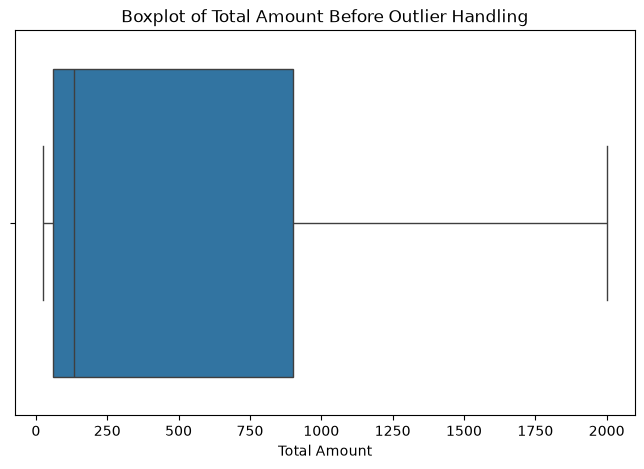

In [44]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df[col])

plt.title(f"Boxplot of {col} Before Outlier Handling")
plt.xlabel(col)

plt.show()
 

In [45]:
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [55]:
 ### Outlier Handling
"""Outliers were detected using the Interquartile Range (IQR) method. Instead of deleting potentially useful observations, extreme values were capped at the lower and upper IQR boundaries. This reduces the influence of extreme values while preserving the records."""

_IncompleteInputError: incomplete input (1176625839.py, line 2)

In [47]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,cust001,male,34,beauty,3,50,150
1,2,2023-02-27,cust002,female,26,clothing,2,500,1000
2,3,2023-01-13,cust003,male,50,electronics,1,30,30
3,4,2023-05-21,cust004,male,37,clothing,1,500,500
4,5,2023-05-06,cust005,male,30,beauty,2,50,100


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


In [50]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1000
Columns: 9


In [51]:
 print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [52]:
 print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [53]:
comparison = pd.DataFrame({
    'Metric': [
        'Rows',
        'Columns',
        'Missing Values',
        'Duplicate Rows'
    ],
    
    'Before Cleaning': [
        original_rows,
        original_columns,
        original_missing,
        original_duplicates
    ],
    
    'After Cleaning': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

comparison

,Metric,Before Cleaning,After Cleaning
0,Rows,1000,1000
1,Columns,9,9
2,Missing Values,0,0
3,Duplicate Rows,0,0


In [54]:
df.to_csv("cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
# Conclusion

"""The dataset was successfully cleaned and transformed into an analysis-ready dataset.

The following data-cleaning operations were performed:

1. Initial data inspection and quality assessment.
2. Missing-value identification and handling.
3. Duplicate record removal.
4. Standardisation of categorical values.
5. Correction of data types.
6. Outlier detection using the IQR method.
7. Outlier handling using value capping.
8. Final quality checks.
9. Export of the cleaned dataset.

The cleaned dataset is now suitable for further analysis and machine learning applications."""